# 🧠 Binary DeepFake Classification — EfficientNet-B4

**Dataset layout (single zip):**
```
openfake_subset.zip
├── images/
│   ├── 1.jpg
│   ├── 2.jpg  ...
└── metadata.csv    columns: image_path | prompt | label | model
```

**Label logic (binary):**
- `label == 'real'`  →  class 0
- anything else      →  class 1 (fake)

The `model` column is ignored for classification.

> Set runtime to **GPU → T4** before running.

## 1. Mount Drive & Extract Dataset

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os, zipfile

# ── ONLY THING YOU NEED TO CHANGE ────────────────────────────────────────────
ZIP_PATH   = '/content/drive/MyDrive/Image Processing Project/openfake_subset.zip'
EXTRACT_TO = '/content/dataset'
# ─────────────────────────────────────────────────────────────────────────────

if not os.path.exists(EXTRACT_TO):
    print('Extracting...')
    with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
        zf.extractall(EXTRACT_TO)
    print('Done.')
else:
    print('Already extracted.')

# Step into single top-level folder if the zip has one
entries = os.listdir(EXTRACT_TO)
DATA_ROOT = (
    os.path.join(EXTRACT_TO, entries[0])
    if len(entries) == 1 and os.path.isdir(os.path.join(EXTRACT_TO, entries[0]))
    else EXTRACT_TO
)

CSV_PATH    = os.path.join(DATA_ROOT, 'metadata.csv')
IMAGES_DIR  = os.path.join(DATA_ROOT, 'images')

print(f'Data root  : {DATA_ROOT}')
print(f'CSV        : {CSV_PATH}')
print(f'Images dir : {IMAGES_DIR}')
print(f'Image count: {len(os.listdir(IMAGES_DIR)):,}')

Extracting...
Done.
Data root  : /content/dataset
CSV        : /content/dataset/metadata.csv
Images dir : /content/dataset/images
Image count: 9,000


## 2. Install & Import

In [ ]:
!pip install timm --quiet

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim.lr_scheduler import CosineAnnealingLR
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

import timm
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, roc_auc_score, RocCurveDisplay
)
from tqdm.notebook import tqdm
import copy, time, warnings, shutil, json
warnings.filterwarnings('ignore')

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device : {DEVICE}')
if DEVICE.type == 'cuda':
    print(f'GPU    : {torch.cuda.get_device_name(0)}')

Device : cuda
GPU    : Tesla T4


## 3. Load CSV → Build Binary Labels

- `label == 'real'` → **0**  
- anything else (any fake/generated label) → **1**

In [ ]:
# ── Read CSV ──────────────────────────────────────────────────────────────────
# Try tab first (matches your sample), fall back to comma
try:
    df = pd.read_csv(CSV_PATH, sep='\t')
    assert len(df.columns) > 1, 'Only 1 column parsed — trying comma separator'
except Exception:
    df = pd.read_csv(CSV_PATH, sep=',')

print('CSV shape  :', df.shape)
print('Columns    :', df.columns.tolist())
print('\nSample rows:')
display(df.head(3))

CSV shape  : (8989, 4)
Columns    : ['image_path', 'prompt', 'label', 'model']

Sample rows:


,image_path,prompt,label,model
0,/content/openfake_subset/images/0.jpg,A photograph of a person wearing a white ribbe...,real,real
1,/content/openfake_subset/images/1.jpg,A promotional poster for Bill Moyers' Faith & ...,real,real
2,/content/openfake_subset/images/2.jpg,A promotional poster showcasing a cozy living ...,real,real


In [ ]:
# ── Resolve image paths ───────────────────────────────────────────────────────
# The CSV stores full paths like /content/openfake_subset/images/6.jpg
# We only need the filename and join it to our local IMAGES_DIR
df['filename']      = df['image_path'].apply(os.path.basename)
df['resolved_path'] = df['filename'].apply(lambda f: os.path.join(IMAGES_DIR, f))

# ── Binary label: real=0, fake=1 ──────────────────────────────────────────────
df['binary_label'] = df['label'].apply(
    lambda x: 0 if str(x).strip().lower() == 'real' else 1
)

# Drop rows where the image file doesn't actually exist
exists_mask = df['resolved_path'].apply(os.path.exists)
missing = (~exists_mask).sum()
if missing > 0:
    print(f'Warning: {missing} image files not found — dropping them.')
df = df[exists_mask].reset_index(drop=True)

CLASS_NAMES = ['real', 'fake']

print(f'Total usable samples : {len(df):,}')
print(f"Real  (0) : {(df['binary_label']==0).sum():,}")
print(f"Fake  (1) : {(df['binary_label']==1).sum():,}")

Total usable samples : 8,989
Real  (0) : 3,000
Fake  (1) : 5,989


## 4. Configuration

In [ ]:
CFG = {
    # Model
    'model_name'    : 'efficientnet_b4',
    'num_classes'   : 2,
    'img_size'      : 256,
    'pretrained'    : True,

    # Data splits
    'train_frac'    : 0.8,
    'val_frac'      : 0.1,

    # Training
    'epochs'        : 30,
    'batch_size'    : 32,
    'num_workers'   : 2,

    # Learning rates (two param groups)
    'lr_head'       : 1e-3,
    'lr_backbone'   : 1e-4,
    'weight_decay'  : 1e-4,


    # Early stopping
    'patience'      : 5,

    # Save paths
    'save_path'     : '/content/best_model.pth',
    'drive_save'    : '/content/drive/MyDrive/EfficientModel/efficientnet_deepfake_binary.pth',

    'seed'          : 42,
}

torch.manual_seed(CFG['seed'])
np.random.seed(CFG['seed'])
print('Config set.')

Config set.


## 5. Stratified Train / Val / Test Split

In [ ]:

real_df = df[df['binary_label'] == 0].copy()
fake_df = df[df['binary_label'] == 1].copy()

def split_df(dataframe, splits=(0.8, 0.1, 0.1), seed=42):
    dataframe = dataframe.sample(frac=1, random_state=seed).reset_index(drop=True)

    n = len(dataframe)
    n_train = int(n * splits[0])
    n_val   = int(n * splits[1])

    return {
        'train': dataframe.iloc[:n_train],
        'val'  : dataframe.iloc[n_train:n_train+n_val],
        'test' : dataframe.iloc[n_train+n_val:]
    }

real_splits = split_df(
    real_df,
    splits=(CFG['train_frac'], CFG['val_frac'], 1 - CFG['train_frac'] - CFG['val_frac']),
    seed=CFG['seed']
)

fake_splits = split_df(
    fake_df,
    splits=(CFG['train_frac'], CFG['val_frac'], 1 - CFG['train_frac'] - CFG['val_frac']),
    seed=CFG['seed']
)

df_train = pd.concat([real_splits['train'], fake_splits['train']]).reset_index(drop=True)
df_val   = pd.concat([real_splits['val'], fake_splits['val']]).reset_index(drop=True)
df_test  = pd.concat([real_splits['test'], fake_splits['test']]).reset_index(drop=True)

# Optional final shuffle
df_train = df_train.sample(frac=1, random_state=CFG['seed']).reset_index(drop=True)
df_val   = df_val.sample(frac=1, random_state=CFG['seed']).reset_index(drop=True)
df_test  = df_test.sample(frac=1, random_state=CFG['seed']).reset_index(drop=True)

for name, split in [('Train', df_train), ('Val', df_val), ('Test', df_test)]:
    r = (split['binary_label'] == 0).sum()
    f = (split['binary_label'] == 1).sum()
    print(f'{name:5s}: {len(split):,} total  |  real={r:,}  fake={f:,}')

Train: 7,191 total  |  real=2,400  fake=4,791
Val  : 898 total  |  real=300  fake=598
Test : 900 total  |  real=300  fake=600


## 6. Dataset Class & Transforms

In [ ]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]
SIZE = CFG['img_size']

train_transforms = transforms.Compose([
    transforms.Resize((SIZE + 32, SIZE + 32)),
    transforms.RandomCrop(SIZE),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1, hue=0.05),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

val_transforms = transforms.Compose([
    transforms.Resize((SIZE + 32, SIZE + 32)),
    transforms.CenterCrop(SIZE),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])


class DeepFakeDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df        = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row   = self.df.iloc[idx]
        img   = Image.open(row['resolved_path']).convert('RGB')
        label = int(row['binary_label'])
        if self.transform:
            img = self.transform(img)
        return img, label


train_dataset = DeepFakeDataset(df_train, train_transforms)
val_dataset   = DeepFakeDataset(df_val,   val_transforms)
test_dataset  = DeepFakeDataset(df_test,  val_transforms)

train_loader = DataLoader(train_dataset, batch_size=CFG['batch_size'],
                          shuffle=True,  num_workers=CFG['num_workers'], pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=CFG['batch_size'],
                          shuffle=False, num_workers=CFG['num_workers'], pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=CFG['batch_size'],
                          shuffle=False, num_workers=CFG['num_workers'], pin_memory=True)

print(f'Train : {len(train_dataset):,} | Val : {len(val_dataset):,} | Test : {len(test_dataset):,}')

Train : 7,191 | Val : 898 | Test : 900


## 7. Sanity Check — Visualise a Batch

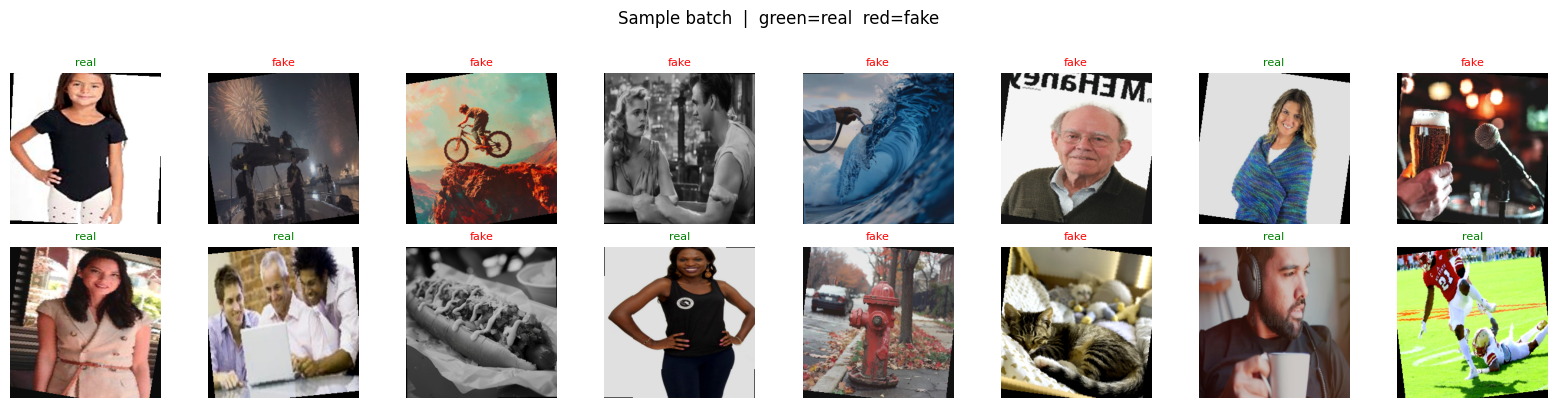

In [ ]:
def denormalise(tensor):
    mean = torch.tensor(IMAGENET_MEAN).view(3,1,1)
    std  = torch.tensor(IMAGENET_STD ).view(3,1,1)
    return (tensor * std + mean).clamp(0, 1)

images, labels = next(iter(train_loader))
n = min(16, len(images))
fig, axes = plt.subplots(2, 8, figsize=(16, 4))
for i, ax in enumerate(axes.flat):
    if i >= n: ax.axis('off'); continue
    ax.imshow(denormalise(images[i]).permute(1,2,0).numpy())
    ax.set_title(CLASS_NAMES[labels[i]], fontsize=8,
                 color='green' if labels[i]==0 else 'red')
    ax.axis('off')
plt.suptitle('Sample batch  |  green=real  red=fake', y=1.01)
plt.tight_layout()
plt.show()

## 8. Model — EfficientNet-B4

In [ ]:
def build_model(cfg):
    return timm.create_model(
        cfg['model_name'],
        pretrained=cfg['pretrained'],
        num_classes=cfg['num_classes']
    )

# def freeze_backbone(model):
#     for name, p in model.named_parameters():
#         if 'classifier' not in name:
#             p.requires_grad = False
def apply_20pct_unfreeze(model):
    """
    Freeze everything, then selectively unfreeze:
      - blocks.5  (second-to-last conv block)
      - blocks.6  (last conv block)
      - conv_head (final conv before pooling)
      - classifier (FC head)
    This gives approximately 20% trainable parameters.
    Stays fixed for the entire training — no mid-training switching.
    """
    # Step 1: freeze everything
    for param in model.parameters():
        param.requires_grad = False

    # Step 2: unfreeze the last ~20%
    UNFREEZE_KEYWORDS = ['bn1.weight','bn1.bias','blocks.1','blocks.2','blocks.4','bn2.bias', 'bn2.weight', 'conv_head', 'classifier']
    for name, param in model.named_parameters():
        if any(kw in name for kw in UNFREEZE_KEYWORDS):
            param.requires_grad = True

# def unfreeze_backbone(model):
#     for p in model.parameters():
#         p.requires_grad = True

def count_params(model):
    total     = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    pct       = 100 * trainable / total
    print(f'Total params     : {total:,}')
    print(f'Trainable params : {trainable:,}  ({pct:.1f}%)')
    print(f'Frozen params    : {total - trainable:,}  ({100 - pct:.1f}%)')
def show_frozen_layers(model):
    """Print which top-level blocks are frozen vs trainable."""
    print('\nLayer status:')
    seen = set()
    for name, param in model.named_parameters():
        top = name.split('.')[0] + '.' + name.split('.')[1] if '.' in name else name
        if top not in seen:
            seen.add(top)
            status = '✅ train' if param.requires_grad else '❄️  frozen'
            print(f'  {status}  {top}')

# def count_trainable(model):
#     return sum(p.numel() for p in model.parameters() if p.requires_grad)

def build_optimizer(model, cfg):
    head_params     = [p for n,p in model.named_parameters()
                       if 'classifier' in n and p.requires_grad]
    backbone_params = [p for n,p in model.named_parameters()
                       if 'classifier' not in n and p.requires_grad]
    groups = [{'params': head_params, 'lr': cfg['lr_head']}]
    if backbone_params:
        groups.append({'params': backbone_params, 'lr': cfg['lr_backbone']})
    return optim.AdamW(groups, weight_decay=cfg['weight_decay'])


model = build_model(CFG).to(DEVICE)
apply_20pct_unfreeze(model)

count_params(model)
show_frozen_layers(model)

print(f'Model      : {CFG["model_name"]}')
print(f'Output     : {CFG["num_classes"]} classes → {CLASS_NAMES}')


model.safetensors:   0%|          | 0.00/77.9M [00:00<?, ?B/s]

Total params     : 17,552,202
Trainable params : 3,462,470  (19.7%)
Frozen params    : 14,089,732  (80.3%)

Layer status:
  ❄️  frozen  conv_stem.weight
  ✅ train  bn1.weight
  ✅ train  bn1.bias
  ❄️  frozen  blocks.0
  ✅ train  blocks.1
  ✅ train  blocks.2
  ❄️  frozen  blocks.3
  ✅ train  blocks.4
  ❄️  frozen  blocks.5
  ❄️  frozen  blocks.6
  ✅ train  conv_head.weight
  ✅ train  bn2.weight
  ✅ train  bn2.bias
  ✅ train  classifier.weight
  ✅ train  classifier.bias
Model      : efficientnet_b4
Output     : 2 classes → ['real', 'fake']


## 9. Class Weights — Handle Imbalance
If real and fake counts are unequal, this prevents the model from just predicting the majority class.

In [ ]:
counts  = df_train['binary_label'].value_counts().sort_index().values  # [n_real, n_fake]
weights = torch.tensor(1.0 / counts, dtype=torch.float32)
weights = weights / weights.sum() * 2   # normalise
weights = weights.to(DEVICE)

criterion = nn.CrossEntropyLoss(weight=weights)

print(f'real weight : {weights[0]:.4f}')
print(f'fake weight : {weights[1]:.4f}')

real weight : 1.3325
fake weight : 0.6675


## 10. Training Loop

In [ ]:
def run_epoch(model, loader, criterion, optimizer=None, phase='train'):
    is_train = phase == 'train'
    model.train() if is_train else model.eval()
    total_loss, correct, total = 0.0, 0, 0

    with torch.set_grad_enabled(is_train):
        for images, labels in tqdm(loader, desc=phase, leave=False):
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            logits = model(images)
            loss   = criterion(logits, labels)

            if is_train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * images.size(0)
            correct    += (logits.argmax(1) == labels).sum().item()
            total      += images.size(0)

    return total_loss / total, correct / total


def train(model, train_loader, val_loader, criterion, cfg):
    optimizer    = build_optimizer(model, cfg)
    scheduler    = CosineAnnealingLR(optimizer, T_max=cfg['epochs'], eta_min=1e-6)
    best_val_acc = 0.0
    best_weights = copy.deepcopy(model.state_dict())
    patience_ctr = 0
    history      = {'train_loss':[], 'val_loss':[], 'train_acc':[], 'val_acc':[]}

    for epoch in range(1, cfg['epochs'] + 1):

        # # Unfreeze backbone after freeze_epochs
        # if epoch == cfg['freeze_epochs'] + 1:
        #     print(f'\n→ Epoch {epoch}: unfreezing backbone for full fine-tuning')
        #     unfreeze_backbone(model)
        #     optimizer = build_optimizer(model, cfg)
        #     scheduler = CosineAnnealingLR(
        #         optimizer,
        #         T_max=cfg['epochs'] - cfg['freeze_epochs'],
        #         eta_min=1e-6
        #     )
        #     print(f'   Trainable params: {count_trainable(model):,}')

        t0 = time.time()
        train_loss, train_acc = run_epoch(model, train_loader, criterion, optimizer, 'train')
        val_loss,   val_acc   = run_epoch(model, val_loader,   criterion, None,      'val')
        scheduler.step()

        history['train_loss'].append(train_loss)
        history['val_loss'  ].append(val_loss)
        history['train_acc' ].append(train_acc)
        history['val_acc'   ].append(val_acc)

        print(f'Epoch [{epoch:02d}/{cfg["epochs"]}]  '
              f'train_loss={train_loss:.4f}  train_acc={train_acc:.4f}  '
              f'val_loss={val_loss:.4f}  val_acc={val_acc:.4f}  '
              f'({time.time()-t0:.0f}s)')

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_weights = copy.deepcopy(model.state_dict())
            torch.save(best_weights, cfg['save_path'])
            print(f'   ✓ Best model saved  (val_acc={best_val_acc:.4f})')
            patience_ctr = 0
        else:
            patience_ctr += 1
            if patience_ctr >= cfg['patience']:
                print(f'\nEarly stopping at epoch {epoch}.')
                break

    model.load_state_dict(best_weights)
    print(f'\nDone. Best val accuracy: {best_val_acc:.4f}')
    return model, history


model, history = train(model, train_loader, val_loader, criterion, CFG)

train:   0%|          | 0/225 [00:00<?, ?it/s]

val:   0%|          | 0/29 [00:00<?, ?it/s]

Epoch [01/30]  train_loss=0.8601  train_acc=0.6582  val_loss=0.6734  val_acc=0.7149  (148s)
   ✓ Best model saved  (val_acc=0.7149)


train:   0%|          | 0/225 [00:00<?, ?it/s]

val:   0%|          | 0/29 [00:00<?, ?it/s]

Epoch [02/30]  train_loss=0.6018  train_acc=0.7404  val_loss=0.5548  val_acc=0.7728  (145s)
   ✓ Best model saved  (val_acc=0.7728)


... (71 outputs left out)

Epoch [26/30]  train_loss=0.1597  train_acc=0.9355  val_loss=0.3116  val_acc=0.8953  (146s)


train:   0%|          | 0/225 [00:00<?, ?it/s]

val:   0%|          | 0/29 [00:00<?, ?it/s]

Epoch [27/30]  train_loss=0.1580  train_acc=0.9385  val_loss=0.3266  val_acc=0.8942  (149s)

Early stopping at epoch 27.

Done. Best val accuracy: 0.8976


## 11. Training Curves

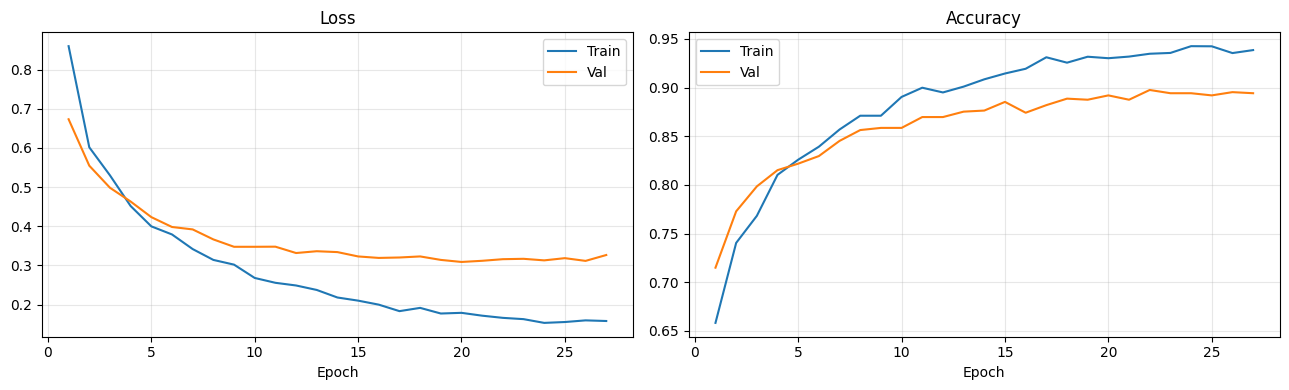

In [ ]:
epochs_ran = range(1, len(history['train_loss']) + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))

ax1.plot(epochs_ran, history['train_loss'], label='Train')
ax1.plot(epochs_ran, history['val_loss'],   label='Val')
ax1.set_title('Loss'); ax1.set_xlabel('Epoch'); ax1.legend(); ax1.grid(alpha=0.3)

ax2.plot(epochs_ran, history['train_acc'], label='Train')
ax2.plot(epochs_ran, history['val_acc'],   label='Val')
ax2.set_title('Accuracy'); ax2.set_xlabel('Epoch'); ax2.legend(); ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 12. Evaluate on Test Set

In [ ]:
model.eval()
all_preds, all_labels, all_probs = [], [], []

with torch.no_grad():
    for images, labels in tqdm(test_loader, desc='Testing'):
        images  = images.to(DEVICE)
        logits  = model(images)
        probs   = torch.softmax(logits, dim=1)[:, 1]   # prob of being FAKE
        preds   = logits.argmax(dim=1)
        all_preds .extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())
        all_probs .extend(probs.cpu().numpy())

print('Classification Report:')
print(classification_report(all_labels, all_preds,
                             target_names=CLASS_NAMES, digits=4))

# ROC-AUC
auc = roc_auc_score(all_labels, all_probs)
print(f'ROC-AUC : {auc:.4f}')

Testing:   0%|          | 0/29 [00:00<?, ?it/s]

Classification Report:
              precision    recall  f1-score   support

        real     0.8280    0.7700    0.7979       300
        fake     0.8889    0.9200    0.9042       600

    accuracy                         0.8700       900
   macro avg     0.8584    0.8450    0.8511       900
weighted avg     0.8686    0.8700    0.8688       900

ROC-AUC : 0.9458


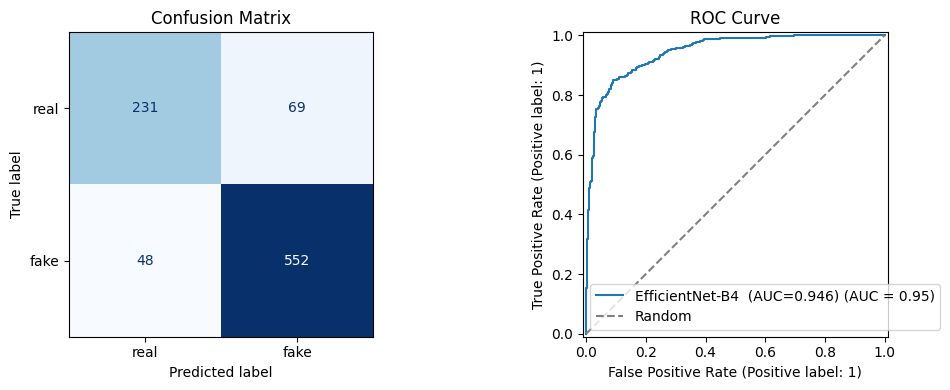

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

# Confusion matrix
cm = confusion_matrix(all_labels, all_preds)
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(
    ax=ax1, cmap='Blues', colorbar=False
)
ax1.set_title('Confusion Matrix')

# ROC curve
RocCurveDisplay.from_predictions(
    all_labels, all_probs,
    name=f'EfficientNet-B4  (AUC={auc:.3f})',
    ax=ax2
)
ax2.plot([0,1],[0,1],'--', color='gray', label='Random')
ax2.set_title('ROC Curve')
ax2.legend()

plt.tight_layout()
plt.show()

## 13. Grad-CAM — What Does the Model Look At?

In [ ]:
!pip install grad-cam --quiet

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 54.2 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


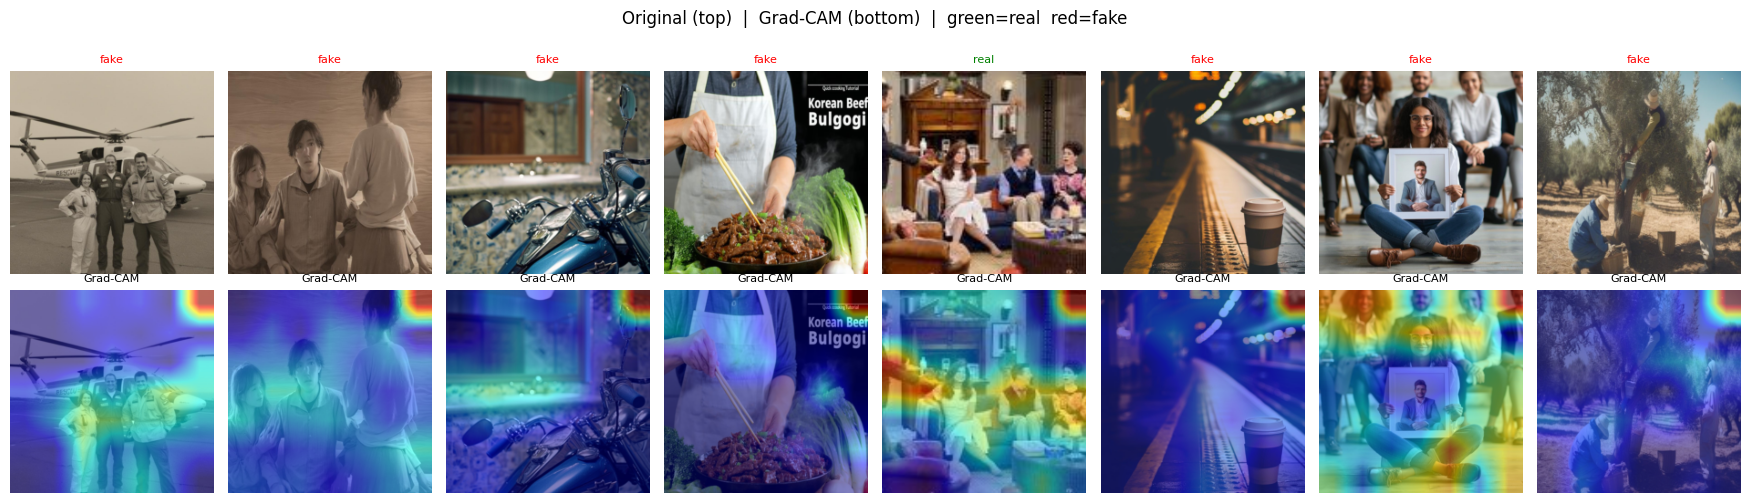

In [ ]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image

target_layer = [model.blocks[-1]]
cam = GradCAM(model=model, target_layers=target_layer)

images, labels = next(iter(val_loader))
n_show = min(8, len(images))

fig, axes = plt.subplots(2, n_show, figsize=(2.2 * n_show, 5))
for i in range(n_show):
    tensor    = images[i].unsqueeze(0).to(DEVICE)
    grayscale = cam(input_tensor=tensor)[0]
    img_np    = denormalise(images[i]).permute(1,2,0).numpy().astype(np.float32)
    cam_img   = show_cam_on_image(img_np, grayscale, use_rgb=True)

    axes[0, i].imshow(img_np)
    axes[0, i].set_title(CLASS_NAMES[labels[i]], fontsize=8,
                          color='green' if labels[i]==0 else 'red')
    axes[0, i].axis('off')
    axes[1, i].imshow(cam_img)
    axes[1, i].set_title('Grad-CAM', fontsize=8)
    axes[1, i].axis('off')

plt.suptitle('Original (top)  |  Grad-CAM (bottom)  |  green=real  red=fake', y=1.01)
plt.tight_layout()
plt.show()

## 14. Save to Google Drive

In [ ]:
shutil.copy(CFG['save_path'], CFG['drive_save'])
print(f'Model saved : {CFG["drive_save"]}')

meta = {'classes': CLASS_NAMES, 'label2idx': {'real': 0, 'fake': 1}}
meta_path = CFG['drive_save'].replace('.pth', '_classes.json')
with open(meta_path, 'w') as f:
    json.dump(meta, f, indent=2)
print(f'Class map   : {meta_path}')

FileNotFoundError: [Errno 2] No such file or directory: '/content/best_model.pth'

In [ ]:
!pip install lime

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 22.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283834 sha256=57f2cddbcbc0f0aa787cda1c3d445917f7a2b9de7dba0eb66c1d6ab29570b6c1
  Stored in directory: /root/.cache/pip/wheels/e7/5d/0e/4b4fff9a47468fed5633211fb3b76d1db43fe806a17fb7486a
Successfully built lime


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import torch
import timm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Recreate model architecture
model = timm.create_model(
    CFG['model_name'],
    pretrained=False,   # False because we are loading saved weights
    num_classes=CFG['num_classes']
)

# Load saved weights
model.load_state_dict(
    torch.load(CFG['drive_save'], map_location=device)
)

model.to(device)
model.eval()

print("Model loaded successfully.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model loaded successfully.


In [ ]:
from lime import lime_image
from skimage.segmentation import mark_boundaries

explainer = lime_image.LimeImageExplainer()

def lime_predict(images_np):
    """Batch predict function for LIME — takes (N, H, W, 3) numpy array."""
    model.eval()
    batch = torch.stack([
        val_transforms(Image.fromarray((img * 255).astype(np.uint8)))
        for img in images_np
    ]).to(DEVICE)
    with torch.no_grad():
        probs = torch.softmax(model(batch), dim=1).cpu().numpy()
    return probs


# Run LIME on a few val images
images, labels = next(iter(val_loader))
n_show = min(4000, len(images))   # LIME is slow — keep to 4

fig, axes = plt.subplots(2, n_show, figsize=(3.5 * n_show, 6))

for i in range(n_show):
    img_np = denormalise(images[i]).permute(1,2,0).numpy().astype(np.float64)

    explanation = explainer.explain_instance(
        img_np,
        lime_predict,
        top_labels=1,
        hide_color=0,
        num_samples=500    # increase to 1000+ for smoother results (slower)
    )

    pred_label = explanation.top_labels[0]
    temp, mask = explanation.get_image_and_mask(
        pred_label,
        positive_only=True,
        num_features=8,
        hide_rest=False
    )

    axes[0,i].imshow(img_np)
    axes[0,i].set_title(f'GT: {CLASS_NAMES[labels[i]]}', fontsize=9,
                         color='green' if labels[i]==0 else 'red')
    axes[0,i].axis('off')

    axes[1,i].imshow(mark_boundaries(temp, mask))
    axes[1,i].set_title(f'LIME → {CLASS_NAMES[pred_label]}', fontsize=9)
    axes[1,i].axis('off')

plt.suptitle('LIME  |  highlighted superpixels = most important regions for prediction', y=1.01)
plt.tight_layout(); plt.show()

ModuleNotFoundError: No module named 'lime'

## 15. Predict on a Single Image

In [ ]:
def predict_image(img_path, model, transform, device):
    img    = Image.open(img_path).convert('RGB')
    tensor = transform(img).unsqueeze(0).to(device)

    model.eval()
    with torch.no_grad():
        probs = torch.softmax(model(tensor), dim=1)[0].cpu()

    pred  = probs.argmax().item()
    label = CLASS_NAMES[pred]
    conf  = probs[pred].item()

    print(f'Prediction : {label}  ({conf:.2%} confidence)')
    print(f'  real prob : {probs[0]:.4f}')
    print(f'  fake prob : {probs[1]:.4f}')

    plt.imshow(img); plt.axis('off')
    plt.title(f'{label}  ({conf:.2%})',
              color='green' if pred == 0 else 'red', fontsize=13)
    plt.show()

# Example:
# predict_image('/content/dataset/images/6.jpg', model, val_transforms, DEVICE)